# 2 · Meta-regression and publication bias

The same BCG dataset, with two questions:

1. Does the **year** of a trial explain part of the heterogeneity?
   (meta-regression / subgroup analysis)
2. Is there a sign of publication bias? (Egger's test, trim-and-fill, funnel
   plot, Baujat plot)

> **中文**　同一个 BCG 数据集，这次问两个问题：
>
> 1. 试验**年代**能不能解释掉这部分异质性？（元回归 / 亚组）
> 2. 有没有发表偏倚的迹象？（Egger 检验、trim-and-fill、漏斗图、Baujat 图）

In [1]:
import math

import numpy as np

import pimeta as ma

In [2]:
study = ["Aronson 1948", "Ferguson & Simes 1949", "Rosenthal et al 1960",
         "Hart & Sutherland 1977", "Frimodt-Moller et al 1973",
         "Stein & Aronson 1953", "Vandiviere et al 1973", "TPT Madras 1980",
         "Coetzee & Berjak 1968", "Rosenthal et al 1961", "Comstock et al 1974",
         "Comstock & Webster 1969", "Comstock et al 1976"]
year = [1948, 1949, 1960, 1977, 1973, 1953, 1973, 1980, 1968, 1961, 1974, 1969, 1976]
tpos = [4, 6, 3, 62, 33, 180, 8, 505, 29, 17, 186, 5, 27]
tneg = [119, 300, 228, 13536, 5036, 1361, 2537, 87886, 7470, 1699, 50448, 2493, 16886]
cpos = [11, 29, 11, 248, 47, 372, 10, 499, 45, 65, 141, 3, 29]
cneg = [128, 274, 209, 12619, 5761, 1079, 619, 87892, 7232, 1600, 27197, 2338, 17825]
print(f"{len(study)} 项试验，共 {sum(tpos) + sum(tneg) + sum(cpos) + sum(cneg):,} 名受试者")

13 项试验，共 357,347 名受试者


In [3]:
es = ma.escalc("RR", ai=tpos, bi=tneg, ci=cpos, di=cneg)

# 用列名 + 字典喂数据，公式接口写 mods，变量名不用抄错
dat = {"study": study, "year": year, "yi": es.yi, "vi": es.vi,
       "tpos": tpos, "tneg": tneg, "cpos": cpos, "cneg": cneg}

null = ma.rma("yi", "vi", method="REML", data=dat)
print(f"无调节变量：tau^2 = {null.tau2:.5f}, I^2 = {null.I2:.2f}%")

无调节变量：tau^2 = 0.31324, I^2 = 92.22%


## Meta-regression: `mods="~ year"`

The coefficient names follow R: `intrcpt` is the intercept and `year` the
slope.

> **中文**　返回的系数名沿用 R：`intrcpt` 是截距，`year` 是斜率。

In [4]:
reg = ma.rma("yi", "vi", mods="~ year", data=dat)

print("系数名 :", reg.coefnames)
print("截距   :", f"{float(reg.b[0]):.6f}")
print("year   :", f"{float(reg.b[1]):.6f}")
print(f"QM     : {reg.QM:.4f} (df={reg.QMdf[0]}, p={reg.QMp:.4f})")
print(f"tau^2  : {null.tau2:.5f} -> {reg.tau2:.5f}")

系数名 : ['intrcpt', 'year']
截距   : -53.171118
year   : 0.026663
QM     : 2.6858 (df=1, p=0.1012)
tau^2  : 0.31324 -> 0.26656


## Subgroups: split by start year

Pool the two groups separately, then compare the within-group τ² against the
between-group difference.

> **中文**　分别合并两组，对比组内 τ² 和组间差异。

In [5]:
early = np.asarray(year) < 1970
yi_arr = np.asarray(es.yi, dtype=float)
vi_arr = np.asarray(es.vi, dtype=float)

fit_early = ma.rma(yi_arr[early], vi_arr[early], method="REML")
fit_late = ma.rma(yi_arr[~early], vi_arr[~early], method="REML")

for label, fit in (("<= 1969", fit_early), (">= 1970", fit_late)):
    rr = math.exp(float(fit.b[0]))
    lo = math.exp(float(fit.ci_lb[0]))
    hi = math.exp(float(fit.ci_ub[0]))
    print(f"{label:8s} k={fit.k}  RR={rr:.4f} [{lo:.4f}, {hi:.4f}]  "
          f"tau^2={fit.tau2:.5f}")

<= 1969  k=7  RR=0.4061 [0.2794, 0.5901]  tau^2=0.12046
>= 1970  k=6  RR=0.5728 [0.3297, 0.9950]  tau^2=0.42222


## Publication bias

`regtest()` is Egger's regression test, `trimfill()` is trim-and-fill. Both are
traditionally only trusted with **k ≥ 10**; here k = 13, just enough.

> **中文**　`regtest()` 是 Egger 的回归检验，`trimfill()` 是 trim-and-fill。传统上要求 **k ≥ 10**，这里 k = 13，刚好够用。

In [6]:
rt = ma.regtest(es.yi, es.vi)
tf = ma.trimfill(es.yi, es.vi)
mb = ma.metabias(null)

print(f"regtest   p = {rt.p:.4f}（斜率 {rt.slope:.4f}）")
print(f"trimfill  补齐 {tf.k0} 项研究，调整后效应 {tf.filled_effect:.4f}")
print(f"metabias  p = {mb.pval:.4g}（{mb.method_bias}）" if mb.pval is not None
      else f"metabias  k={mb.k} < {mb.k_min}，按惯例不报告")

regtest   p = 0.4218（斜率 -0.7632）
trimfill  补齐 1 项研究，调整后效应 -0.6571
metabias  p = 0.1887（Egger）


## Funnel plot

An asymmetric funnel is the usual visual warning sign; the test above puts a
number on it.

> **中文**　漏斗不对称是最常见的视觉警告信号；上面的检验把这个信号变成数字。

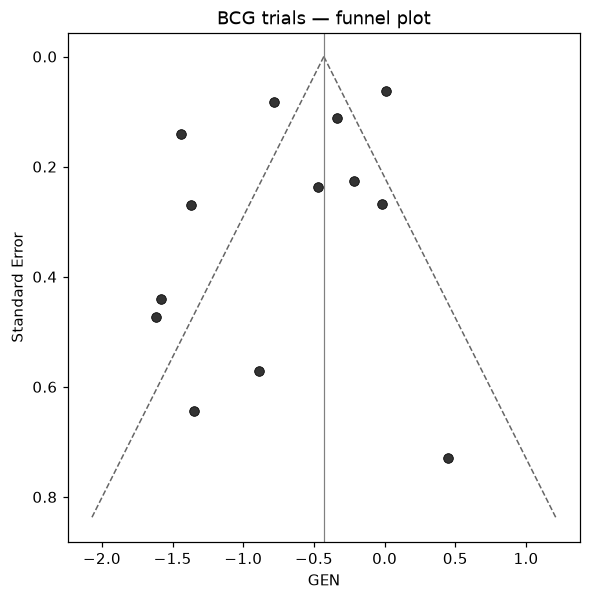

In [7]:
ax = ma.plot(null, which="funnel")
_ = ax.set_title("BCG trials — funnel plot")

## Baujat plot: who contributes heterogeneity, and who moves the pooled result

The horizontal axis is each study's contribution to overall heterogeneity; the
vertical axis is its influence on the pooled effect.

> **中文**　横轴是每个研究对总体异质性的贡献，纵轴是它对合并效应的影响。

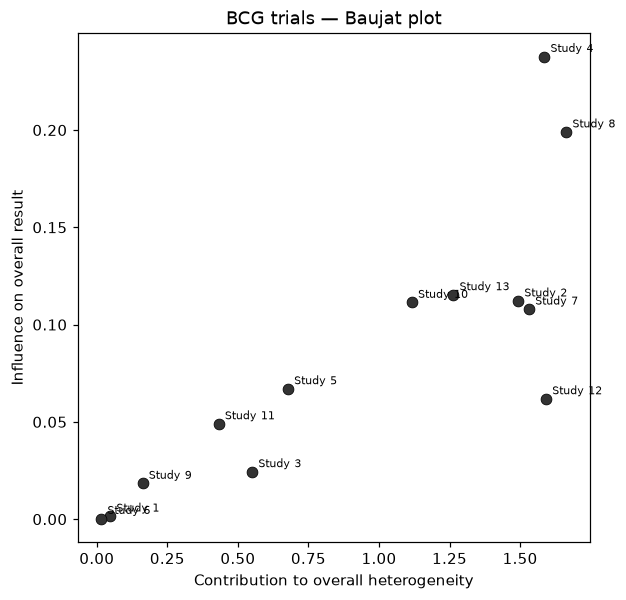

In [8]:
ax = ma.plot(null, which="baujat")
_ = ax.set_title("BCG trials — Baujat plot")

## Reading these results

- In the meta-regression, read the p-value for `year` together with the
  **degrees of freedom of QM** (1 here).
- Within-group τ² is smaller than the overall τ² in both subgroups, so year
  does explain part of the heterogeneity.
- Studies in the top-right of the Baujat plot both **contribute heterogeneity**
  and **move the conclusion**; they deserve a separate look.

Next: [`03-network-meta-analysis.ipynb`](03-network-meta-analysis.ipynb) moves
to a network structure.

> **中文**
> - 元回归里 `year` 的 p 值要结合 **QM 的自由度**（这里 1）一起读；
> - 亚组的组内 τ² 都比总体小，说明年代确实解释了一部分异质性；
> - Baujat 图右上角的研究同时「贡献异质性」又「影响结论」，值得单独检查。
>
> 下一步：[`03-network-meta-analysis.ipynb`](03-network-meta-analysis.ipynb) 换成网状结构。